# Customer Churn Analysis

## Objective

The objective of this analysis is to understand customer churn patterns and identify factors associated with subscription cancellations in the RavenStack SaaS dataset.

## Business Questions

1. How many subscriptions are active versus churned?
2. What is the overall subscription churn percentage?
3. Which subscription plans experience the highest churn?
4. How does churn vary across customer segments?
5. How long do customers typically remain subscribed before churning?
6. What are the most common reasons customers give for leaving?


Load the required datasets

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

subscriptions=pd.read_csv(r"../data/raw/ravenstack_subscriptions.csv")
accounts=pd.read_csv(r"../data/raw/ravenstack_accounts.csv")
churn_events=pd.read_csv(r"../data/raw/ravenstack_churn_events.csv")

print("Subscriptions Shape:",subscriptions.shape)
print("Accounts Shape:",accounts.shape)
print("Churn_events Shape:",churn_events.shape)

Subscriptions Shape: (5000, 14)
Accounts Shape: (500, 10)
Churn_events Shape: (600, 9)


In [4]:
print("Subscription column ",subscriptions.columns.to_list())
print("Accounts column ",accounts.columns.to_list())
print("Churn_events column ",churn_events.columns.to_list())

display(subscriptions.head(10))

Subscription column  ['subscription_id', 'account_id', 'start_date', 'end_date', 'plan_tier', 'seats', 'mrr_amount', 'arr_amount', 'is_trial', 'upgrade_flag', 'downgrade_flag', 'churn_flag', 'billing_frequency', 'auto_renew_flag']
Accounts column  ['account_id', 'account_name', 'industry', 'country', 'signup_date', 'referral_source', 'plan_tier', 'seats', 'is_trial', 'churn_flag']
Churn_events column  ['churn_event_id', 'account_id', 'churn_date', 'reason_code', 'refund_amount_usd', 'preceding_upgrade_flag', 'preceding_downgrade_flag', 'is_reactivation', 'feedback_text']


,subscription_id,account_id,start_date,end_date,plan_tier,seats,mrr_amount,arr_amount,is_trial,upgrade_flag,downgrade_flag,churn_flag,billing_frequency,auto_renew_flag
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,Enterprise,14,2786,33432,False,False,False,True,monthly,True
1,S-0f6f44,A-9b9fe9,2024-06-11,NaN,Pro,17,833,9996,False,False,False,False,monthly,True
2,S-51c0d1,A-659280,2024-11-25,NaN,Enterprise,62,0,0,True,True,False,False,annual,False
3,S-f81687,A-e7a1e2,2024-11-23,2024-12-13,Enterprise,5,995,11940,False,False,False,True,monthly,True
4,S-cff5a2,A-ba6516,2024-01-10,NaN,Enterprise,27,5373,64476,False,False,False,False,monthly,True
5,S-4b9b13,A-fa2041,2024-08-13,NaN,Pro,15,735,8820,False,False,False,False,monthly,True
6,S-dceac6,A-417d2f,2023-12-30,NaN,Enterprise,4,796,9552,False,False,False,False,annual,True
7,S-8cad7b,A-5f2961,2024-12-23,NaN,Basic,16,304,3648,False,False,False,False,annual,True
8,S-24796e,A-cc8c8f,2024-11-27,NaN,Enterprise,23,4577,54924,False,False,False,False,annual,False
9,S-d0c344,A-80eeb6,2024-10-27,NaN,Pro,22,1078,12936,False,False,False,False,annual,False


In [5]:
print("Missing values in Subscriptions:")
display(subscriptions.isnull().sum())

print("Missing values in Accounts:")
display(accounts.isnull().sum())

print("Missing values in Churn Events:")
display(churn_events.isnull().sum())

Missing values in Subscriptions:


subscription_id         0
account_id              0
start_date              0
end_date             4514
plan_tier               0
seats                   0
mrr_amount              0
arr_amount              0
is_trial                0
upgrade_flag            0
downgrade_flag          0
churn_flag              0
billing_frequency       0
auto_renew_flag         0
dtype: int64

Missing values in Accounts:


account_id         0
account_name       0
industry           0
country            0
signup_date        0
referral_source    0
plan_tier          0
seats              0
is_trial           0
churn_flag         0
dtype: int64

Missing values in Churn Events:


churn_event_id                0
account_id                    0
churn_date                    0
reason_code                   0
refund_amount_usd             0
preceding_upgrade_flag        0
preceding_downgrade_flag      0
is_reactivation               0
feedback_text               148
dtype: int64

In [12]:
print("Subscription churn flag distribution:")
display(subscriptions["churn_flag"].value_counts(dropna=False))

Subscription churn flag distribution:


churn_flag
False    4514
True      486
Name: count, dtype: int64

1. How many subscriptions are active versus churned?

In [17]:
churn_flag_counts=subscriptions['churn_flag'].value_counts(dropna=False)

print("Active Subscriptions: ",churn_flag_counts[False])
print("Churn Subscriptions:",churn_flag_counts[True])


Active Subscriptions:  4514
Churn Subscriptions: 486


Text(0, 0.5, 'Churn Flag Count')

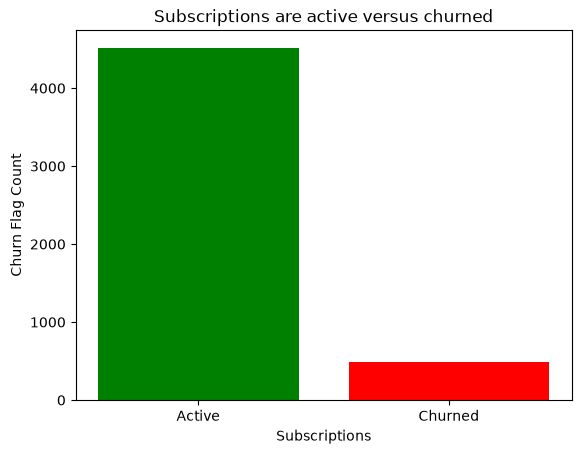

In [23]:
plt.bar(
        ['Active', 'Churned'],
        churn_flag_counts.values,
        color=['green', 'red']
)

plt.title("Subscriptions are active versus churned")
plt.xlabel("Subscriptions")
plt.ylabel("Churn Flag Count")

2. What is the overall subscription churn percentage?

In [25]:
total_subscriptions=len(subscriptions)

churned_subscriptions=subscriptions["churn_flag"].sum()

subscription_churn_rate=churned_subscriptions/total_subscriptions*100

print("Total Subscriptions:",total_subscriptions)
print("Churned Subscriptions:",churned_subscriptions)
print(f"Subscription Churn percentage: {subscription_churn_rate:.2f}%")

Total Subscriptions: 5000
Churned Subscriptions: 486
Subscription Churn percentage: 9.72%



3. Which subscription plans experience the highest churn?

In [35]:
# Group subscriptions by plan and calculate churn statistics
plan_churn=(
    subscriptions
    .groupby('plan_tier')
    .agg(
        total_subscriptions=('subscription_id','count'),
        churned_subscriptions=('churn_flag','sum')
    )
    .reset_index()
)

# Calculate churn percentage for each plan
plan_churn['churn_percentage']=(
    plan_churn['churned_subscriptions']/plan_churn['total_subscriptions']*100
)

# Sort plans by churn percentage

plan_churn = plan_churn.sort_values(
    by = 'churn_percentage'
    ,ascending=False
)

display(plan_churn)

,plan_tier,total_subscriptions,churned_subscriptions,churn_percentage
1,Enterprise,1723,172,9.982589
2,Pro,1675,162,9.671642
0,Basic,1602,152,9.488140


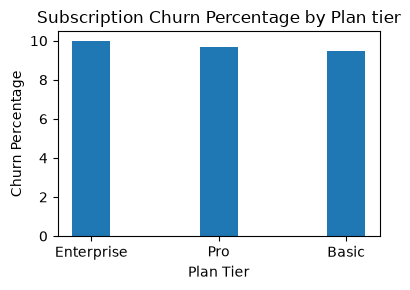

In [48]:
plt.figure(figsize=(4,3))

plt.bar(
    plan_churn['plan_tier'],
    plan_churn['churn_percentage'],
    width=0.3
)

plt.title("Subscription Churn Percentage by Plan tier")
plt.xlabel("Plan Tier")
plt.ylabel("Churn Percentage")

plt.tight_layout()
plt.show()


4. How does churn vary across customer segments?

In [55]:
# Group Customer by industry and calculate churn statistics
industry_churn=(
    accounts
    .groupby('industry')
    .agg(
        total_accounts=('account_id','count'),
        churned_accounts=('churn_flag','sum')
    )
    .reset_index()
)

# Calculate churn percentage for each industry
industry_churn['churn_percentage']=(
    industry_churn['churned_accounts']/industry_churn['total_accounts']*100
)

# Sort plans by churn percentage
industry_churn= industry_churn.sort_values(
    by='churn_percentage',
    ascending=False       
)
display(industry_churn)

,industry,total_accounts,churned_accounts,churn_percentage
1,DevTools,113,35,30.973451
3,FinTech,112,25,22.321429
4,HealthTech,96,21,21.875000
2,EdTech,79,13,16.455696
0,Cybersecurity,100,16,16.000000


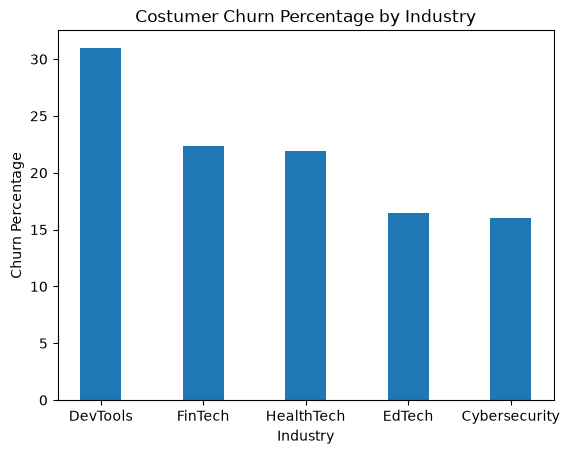

In [57]:
plt.bar(
    industry_churn['industry']
    ,industry_churn['churn_percentage']
    ,width=0.4
)

plt.title("Costumer Churn Percentage by Industry")
plt.xlabel("Industry")
plt.ylabel('Churn Percentage')

plt.show()

- A better one

In [65]:
subscription_accounts=subscriptions.merge(
    accounts[['account_id','industry']],
    on='account_id',
    how='left'
)   

display(subscription_accounts.head())

,subscription_id,account_id,start_date,end_date,plan_tier,seats,mrr_amount,arr_amount,is_trial,upgrade_flag,downgrade_flag,churn_flag,billing_frequency,auto_renew_flag,industry
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,Enterprise,14,2786,33432,False,False,False,True,monthly,True,DevTools
1,S-0f6f44,A-9b9fe9,2024-06-11,NaN,Pro,17,833,9996,False,False,False,False,monthly,True,EdTech
2,S-51c0d1,A-659280,2024-11-25,NaN,Enterprise,62,0,0,True,True,False,False,annual,False,FinTech
3,S-f81687,A-e7a1e2,2024-11-23,2024-12-13,Enterprise,5,995,11940,False,False,False,True,monthly,True,Cybersecurity
4,S-cff5a2,A-ba6516,2024-01-10,NaN,Enterprise,27,5373,64476,False,False,False,False,monthly,True,FinTech


In [66]:
industry_churn = (
    subscription_accounts
    .groupby("industry")
    .agg(
        total_subscriptions=("subscription_id", "count"),
        churned_subscriptions=("churn_flag", "sum")
    )
    .reset_index()
)

industry_churn["churn_percentage"] = (
    industry_churn["churned_subscriptions"]
    / industry_churn["total_subscriptions"]
    * 100
)

industry_churn = industry_churn.sort_values(
    "churn_percentage",
    ascending=False
)

display(industry_churn)

,industry,total_subscriptions,churned_subscriptions,churn_percentage
1,DevTools,1158,125,10.794473
0,Cybersecurity,1008,103,10.218254
4,HealthTech,949,96,10.115911
3,FinTech,1100,96,8.727273
2,EdTech,785,66,8.407643


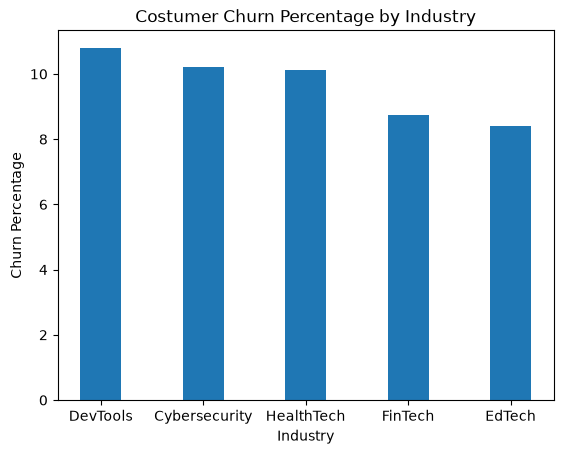

In [67]:
plt.bar(
    industry_churn['industry']
    ,industry_churn['churn_percentage']
    ,width=0.4
)

plt.title("Costumer Churn Percentage by Industry")
plt.xlabel("Industry")
plt.ylabel('Churn Percentage')

plt.show()

5. How long do customers typically remain subscribed before churning?

In [76]:
display(subscriptions.head())
display(churn_events.head())

,subscription_id,account_id,start_date,end_date,plan_tier,seats,mrr_amount,arr_amount,is_trial,upgrade_flag,downgrade_flag,churn_flag,billing_frequency,auto_renew_flag
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,Enterprise,14,2786,33432,False,False,False,True,monthly,True
1,S-0f6f44,A-9b9fe9,2024-06-11,NaT,Pro,17,833,9996,False,False,False,False,monthly,True
2,S-51c0d1,A-659280,2024-11-25,NaT,Enterprise,62,0,0,True,True,False,False,annual,False
3,S-f81687,A-e7a1e2,2024-11-23,2024-12-13,Enterprise,5,995,11940,False,False,False,True,monthly,True
4,S-cff5a2,A-ba6516,2024-01-10,NaT,Enterprise,27,5373,64476,False,False,False,False,monthly,True


,churn_event_id,account_id,churn_date,reason_code,refund_amount_usd,preceding_upgrade_flag,preceding_downgrade_flag,is_reactivation,feedback_text
0,C-816288,A-c37cab,2024-10-27,pricing,4.03,False,False,False,switched to competitor
1,C-5a81e7,A-37f969,2024-06-25,support,96.45,True,False,False,NaN
2,C-a174be,A-b07346,2024-11-12,budget,0.00,False,False,False,missing features
3,C-accb39,A-1e50e0,2023-11-01,budget,54.94,False,False,False,switched to competitor
4,C-92f889,A-956988,2024-12-30,unknown,0.00,False,True,True,too expensive


In [70]:
subscriptions['start_date']=pd.to_datetime(
    subscriptions['start_date']
)

subscriptions['end_date']=pd.to_datetime(
    subscriptions['end_date']
)

print("Start date datatype: ",subscriptions['start_date'].dtype)
print("End date datatype:",subscriptions['end_date'].dtype)

Start date datatype:  datetime64[us]
End date datatype: datetime64[us]


In [73]:
churned=subscriptions[
    subscriptions['churn_flag']== True
].copy()

churned['subscription_duration_days']=(
    churned['end_date']-churned['start_date']
).dt.days

display(
    churned[[
        'subscription_id',
        'account_id',
        'start_date',
        'end_date',
        'subscription_duration_days'
        ]].head()
)

,subscription_id,account_id,start_date,end_date,subscription_duration_days
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,111
3,S-f81687,A-e7a1e2,2024-11-23,2024-12-13,20
16,S-13939b,A-86902e,2023-07-21,2024-08-03,379
17,S-9333c5,A-ef84cf,2024-06-06,2024-08-13,68
21,S-3bd427,A-2e3bad,2024-12-04,2024-12-27,23


In [75]:
print("subscription duration Summary (days):")

display(
    churned['subscription_duration_days'].describe()
)

subscription duration Summary (days):


count    486.000000
mean      88.055556
std      110.728176
min        0.000000
25%       11.000000
50%       42.000000
75%      120.750000
max      624.000000
Name: subscription_duration_days, dtype: float64

6. What are the most common reasons customers give for leaving?

In [78]:
print("Churn reason counts:")

display(
    churn_events["reason_code"]
    .value_counts(dropna=False)
)

Churn reason counts:


reason_code
features      114
support       104
budget        104
unknown        95
competitor     92
pricing        91
Name: count, dtype: int64

In [77]:
churn_reason_summary = (
    churn_events["reason_code"]
    .value_counts(dropna=False)
    .rename_axis("reason_code")
    .reset_index(name="event_count")
)

churn_reason_summary["percentage"] = (
    churn_reason_summary["event_count"]
    / len(churn_events)
    * 100
)

display(churn_reason_summary)

,reason_code,event_count,percentage
0,features,114,19.000000
1,support,104,17.333333
2,budget,104,17.333333
3,unknown,95,15.833333
4,competitor,92,15.333333
5,pricing,91,15.166667


In [79]:
print("Churn reason counts:")

display(
    churn_events["reason_code"]
    .value_counts(dropna=False)
)

Churn reason counts:


reason_code
features      114
support       104
budget        104
unknown        95
competitor     92
pricing        91
Name: count, dtype: int64

- Features (19%) is the most frequently recorded churn reason. This suggests that investigating feature gaps or product expectations may be worthwhile.
- Support (17.33%) and Budget (17.33%) are tied for second place.
- Unknown (15.83%) represents events without a specific known reason, according to the dataset's category.
- Competitor (15.33%) and Pricing (15.17%) are also common recorded reasons.

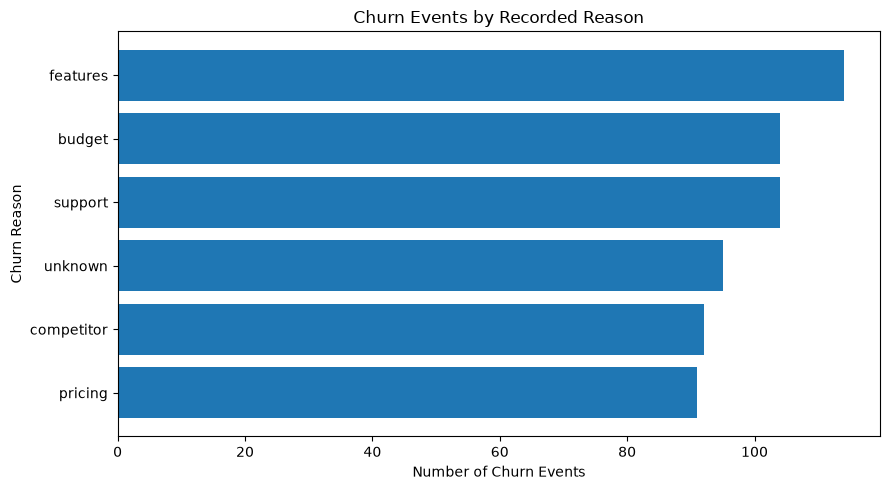

In [80]:
# Sort reasons by event count
churn_reason_chart = churn_reason_summary.sort_values(
    "event_count",
    ascending=True
)

# Create a horizontal bar chart
plt.figure(figsize=(9, 5))

plt.barh(
    churn_reason_chart["reason_code"].fillna("Missing"),
    churn_reason_chart["event_count"]
)

plt.title("Churn Events by Recorded Reason")
plt.xlabel("Number of Churn Events")
plt.ylabel("Churn Reason")

plt.tight_layout()
plt.show()

In [81]:
print(
    "Missing churn reasons:",
    churn_events["reason_code"].isnull().sum()
)

print(
    "Unknown reason events:",
    churn_events["reason_code"]
    .eq("unknown")
    .sum()
)

Missing churn reasons: 0
Unknown reason events: 95


## Customer Churn Analysis Conclusion

The analysis examined subscription churn across plans and industries, subscription duration before churn, and recorded churn reasons. The findings and potential business recommendations have been documented in the customer churn analysis report.

See `docs/customer_churn_analysis_report.md` for the complete report.
